# Lab assignment №1, part 3

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the third part of the assignment. First and second parts are waiting for you in the same directory.*__

##  Part 3. SVM and kernels

Kernels concept get adopted in variety of ML algorithms (e.g. Kernel PCA, Gaussian Processes, kNN, ...).

So in this task you are to examine kernels for SVM algorithm applied to rather simple artificial datasets.

To make it clear: we will work with the classification problem through the whole notebook. 

In [1]:
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt
import numpy as np

Let's generate our dataset and take a look on it.

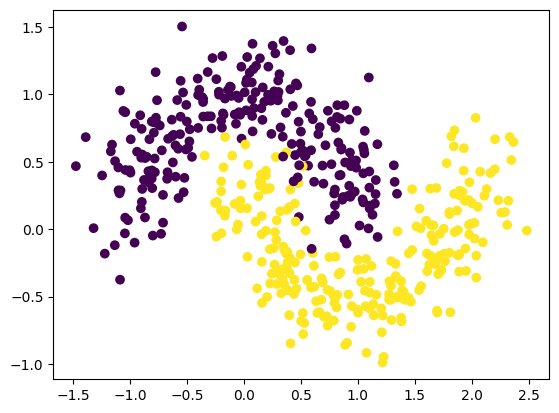

In [2]:
moons_points, moons_labels = make_moons(n_samples=500, noise=0.2, random_state=42)
plt.scatter(moons_points[:, 0], moons_points[:, 1], c=moons_labels)

### Вспомогательная функция для областей решений

Почти в каждом пункте понадобится рисовать **decision regions** — как классификатор делит плоскость между классами. Чтобы не копировать один и тот же код, напишем функцию `plot_decisions(estimator, X, y)`:

- обучает переданную модель на `(X, y)`;
- закрашивает плоскость цветом предсказанного класса через `mlxtend.plotting.plot_decision_regions`;
- подписывает accuracy на обучающей выборке и возвращает её значение.

Для синтетических двумерных данных это самый наглядный способ увидеть форму границы: линейная она, полиномиальная или замкнутая.


In [3]:
from sklearn.metrics import accuracy_score
from mlxtend.plotting import plot_decision_regions


def plot_decisions(estimator, X, y, title=None, ax=None):
    """Обучает estimator на (X, y), рисует области решений,
    возвращает accuracy на этой же выборке."""
    estimator.fit(X, y)
    acc = accuracy_score(y, estimator.predict(X))

    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))

    plot_decision_regions(X, y, clf=estimator, legend=2, ax=ax)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(title if title is not None else type(estimator).__name__)
    ax.text(0.02, 0.98, 'accuracy = %.3f' % acc, transform=ax.transAxes,
            va='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    return acc


## 1.1 Pure models.
First let's try to solve this case with good old Logistic Regression and simple (linear kernel) SVM classifier.

Train LR and SVM classifiers (choose params by hand, no CV or intensive grid search neeeded) and plot their decision regions. Calculate one preffered classification metric.

Describe results in one-two sentences.

_Tip:_ to plot classifiers decisions you colud use either sklearn examples ([this](https://scikit-learn.org/stable/auto_examples/neural_networks/plot_mlp_alpha.html#sphx-glr-auto-examples-neural-networks-plot-mlp-alpha-py) or any other) and mess with matplotlib yourself or great [mlxtend](https://github.com/rasbt/mlxtend) package (see their examples for details)

_Pro Tip:_ wirte function `plot_decisions` taking a dataset and an estimator and plotting the results cause you want to use it several times below

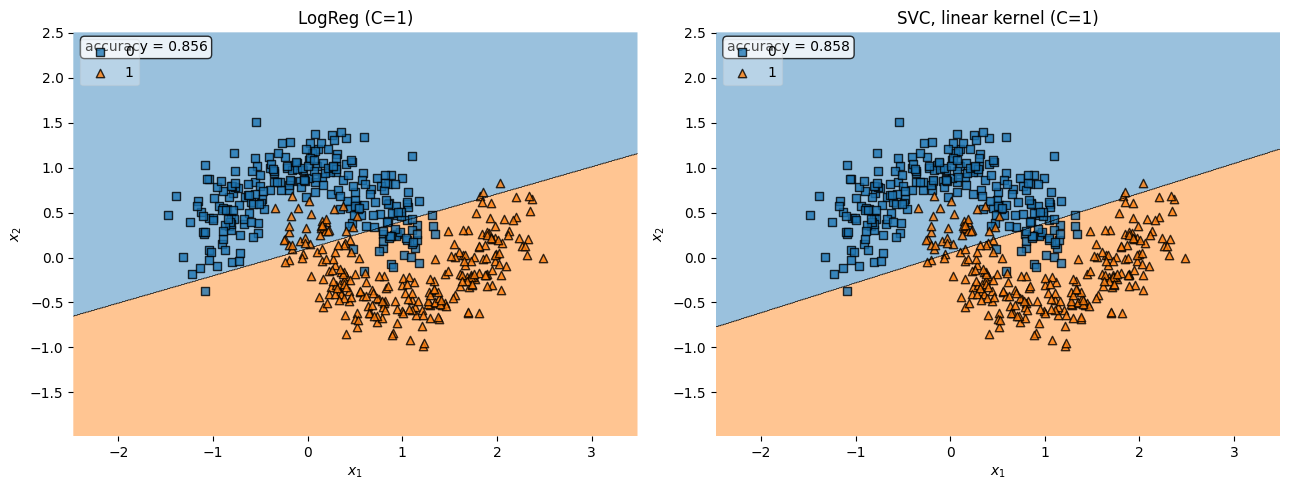

LogReg   : train acc = 0.856, 5-fold CV acc = 0.858, f1_macro = 0.856
SVC linear: train acc = 0.858, 5-fold CV acc = 0.852, f1_macro = 0.858


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, f1_score

# Параметры подобраны вручную: C=1 — разумный компромисс между шириной
# «полосы» и штрафом за ошибки, сетку в этом пункте не крутим.
lr = LogisticRegression(C=1.0, max_iter=1000)
svm_linear = SVC(kernel='linear', C=1.0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
acc_lr = plot_decisions(lr, moons_points, moons_labels, 'LogReg (C=1)', ax=axes[0])
acc_svm = plot_decisions(svm_linear, moons_points, moons_labels,
                         'SVC, linear kernel (C=1)', ax=axes[1])
plt.tight_layout()
plt.show()

# Метрика: accuracy на 5-фолдовой CV (train-accuracy из plot_decisions — для справки).
cv_lr = cross_val_score(LogisticRegression(C=1.0, max_iter=1000),
                        moons_points, moons_labels, cv=5, scoring='accuracy').mean()
cv_svm = cross_val_score(SVC(kernel='linear', C=1.0),
                         moons_points, moons_labels, cv=5, scoring='accuracy').mean()

for name, model, train_acc, cv_acc in (
        ('LogReg   ', lr, acc_lr, cv_lr),
        ('SVC linear', svm_linear, acc_svm, cv_svm)):
    print('%s: train acc = %.3f, 5-fold CV acc = %.3f, f1_macro = %.3f'
          % (name, train_acc, cv_acc,
             f1_score(moons_labels, model.predict(moons_points), average='macro')))


**Результаты.** LogReg (`C=1`) и линейный SVC (`C=1`) дают практически одинаковое качество: 5-фолдовая CV accuracy **0.858** и **0.852**, `f1_macro` на всей выборке 0.856 и 0.858. Разница в пределах разброса по фолдам — обе модели строят одну прямую.

**Вывод.** Линейная граница проводит прямую примерно посередине между «лунами» и отделяет верхний рог от нижнего, поэтому точки у изгибов оказываются не с той стороны. Данные нелинейно разделимы, и подбор `C` сдвигает и наклоняет прямую, но не меняет её форму: ограничение здесь — в гипотезе модели, а не в регуляризации. Отсюда переход к ядрам в п. 1.2.


## 1.2 Kernel tirck

Now use different kernels (`poly`, `rbf`, `sigmoid`) on SVC to get better results. Play `degree` parameter and others.

For each kernel estimate optimal params, plot decision regions, calculate metric you've chosen eariler.

Write couple of sentences on:

* What have happenned with classification quality?
* How did decision border changed for each kernel?
* What `degree` have you chosen and why?

poly degree=2: C=10, coef0=1.0, CV acc=0.848
poly degree=3: C=10, coef0=1.0, CV acc=0.972
poly degree=4: C=10, coef0=1.0, CV acc=0.976
Выбранная степень: 4
poly     {'svc__C': 10, 'svc__coef0': 1.0, 'svc__degree': 4}  train acc = 0.986, f1_macro = 0.986
rbf      {'svc__C': 1, 'svc__gamma': 2.0}                     train acc = 0.978, f1_macro = 0.978
sigmoid  {'svc__C': 1, 'svc__gamma': 0.1}                     train acc = 0.850, f1_macro = 0.850


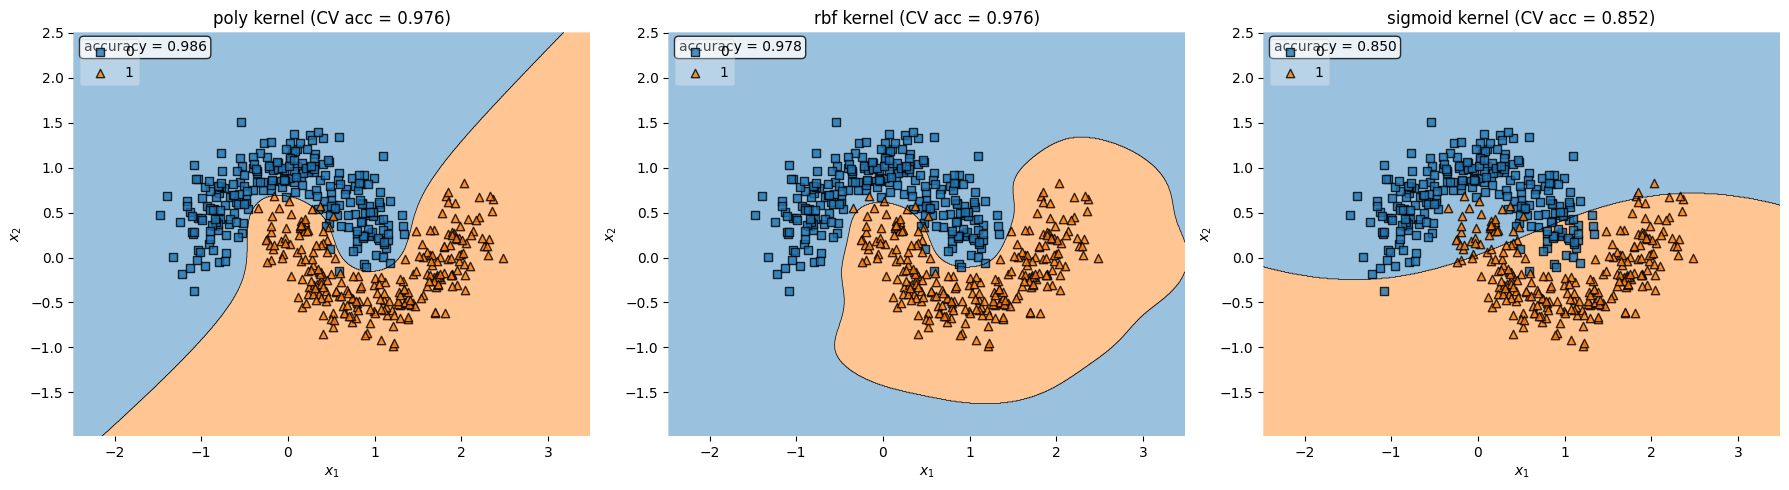

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV


def best_svc(kernel, grid, X, y):
    """Подбирает гиперпараметры SVC по 5-фолдовой CV.
    StandardScaler внутри Pipeline: ядро сравнивает расстояния, и масштаб
    осей должен быть одинаковым."""
    pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel=kernel))])
    search = GridSearchCV(pipe, grid, cv=5, scoring='accuracy')
    search.fit(X, y)
    return search


# 1) Сначала отвечаем на вопрос про degree: сравниваем степени полиномиального ядра.
degree_scores = {}
for degree in (2, 3, 4):
    search = best_svc('poly',
                      {'svc__degree': [degree], 'svc__C': [0.1, 1, 10],
                       'svc__coef0': [0.0, 1.0]},
                      moons_points, moons_labels)
    degree_scores[degree] = search.best_score_
    print('poly degree=%d: C=%.3g, coef0=%.1f, CV acc=%.3f'
          % (degree, search.best_params_['svc__C'],
             search.best_params_['svc__coef0'], search.best_score_))

best_degree = max(degree_scores, key=degree_scores.get)
print('Выбранная степень:', best_degree)

# 2) Подбираем параметры для каждого ядра.
searches = {
    'poly': best_svc('poly',
                     {'svc__degree': [best_degree], 'svc__C': [0.1, 1, 10],
                      'svc__coef0': [0.0, 1.0]},
                     moons_points, moons_labels),
    'rbf': best_svc('rbf',
                    {'svc__C': [0.1, 1, 10, 100],
                     'svc__gamma': ['scale', 0.1, 0.5, 1.0, 2.0]},
                    moons_points, moons_labels),
    'sigmoid': best_svc('sigmoid',
                        {'svc__C': [0.1, 1, 10], 'svc__gamma': ['scale', 0.1, 1.0]},
                        moons_points, moons_labels),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (kernel, search) in zip(axes, searches.items()):
    acc = plot_decisions(search.best_estimator_, moons_points, moons_labels,
                         '%s kernel (CV acc = %.3f)' % (kernel, search.best_score_),
                         ax=ax)
    y_pred = search.best_estimator_.predict(moons_points)
    print('%-8s %-52s train acc = %.3f, f1_macro = %.3f'
          % (kernel, search.best_params_, acc,
             f1_score(moons_labels, y_pred, average='macro')))
plt.tight_layout()
plt.show()


**Что произошло с качеством.**

| Ядро | Лучшие параметры | CV accuracy | train accuracy | `f1_macro` |
|---|---|---|---|---|
| `poly` | `degree=4`, `C=10`, `coef0=1` | **0.976** | 0.986 | 0.986 |
| `rbf` | `C=1`, `gamma=2` | **0.976** | 0.978 | 0.978 |
| `sigmoid` | `C=1`, `gamma=0.1` | 0.852 | 0.850 | 0.850 |

Для полиномиального ядра: `degree=2` — 0.848, `degree=3` — 0.972, `degree=4` — 0.976.

`poly` и `rbf` поднимают accuracy с ≈0.85 (п. 1.1) до **0.976**: ошибки остаются только на стыке классов, где из-за шума (`noise=0.2`) точки разных классов перемешаны. `sigmoid` результата не даёт — 0.852, ровно на уровне линейной модели.

**Как изменилась граница.**

- `poly` (`degree=4`) — гладкая кривая четвёртого порядка: две дуги, огибающие «луны». При `degree=2` кривизны не хватает (0.848, практически как у прямой), начиная с `degree=3` граница проходит по зазору между классами.
- `rbf` — замкнутые локальные области вокруг каждого класса: гауссово ядро зависит только от расстояния до опорных векторов, поэтому граница повторяет форму облака.
- `sigmoid` — снова почти прямая с плавным переходом; это ядро плохо соответствует геометрии «лун».

**Какая степень выбрана и почему.** По CV лучшая — `degree=4` (0.976), `degree=3` даёт 0.972, то есть разница в пределах шума, а `degree=2` недостаточна. Останавливаюсь на 4 как формально лучшей на проверенной сетке; дальше степень не увеличивал, потому что прирост уже нулевой, а риск переобучения и стоимость растут.


## 1.3 Simpler solution (of a kind)
What is we could use Logisitc Regression to successfully solve this task?

Feature generation is a thing to help here. Different techniques of feature generation are used in real life, couple of them will be covered in additional lectures.

In particular case simple `PolynomialFeatures` ([link](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)) are able to save the day.

Generate the set of new features, train LR on it, plot decision regions, calculate metric.

* Comare SVM's results with this solution (quality, borders type)
* What degree of PolynomialFeatures have you used? Compare with same SVM kernel parameter.

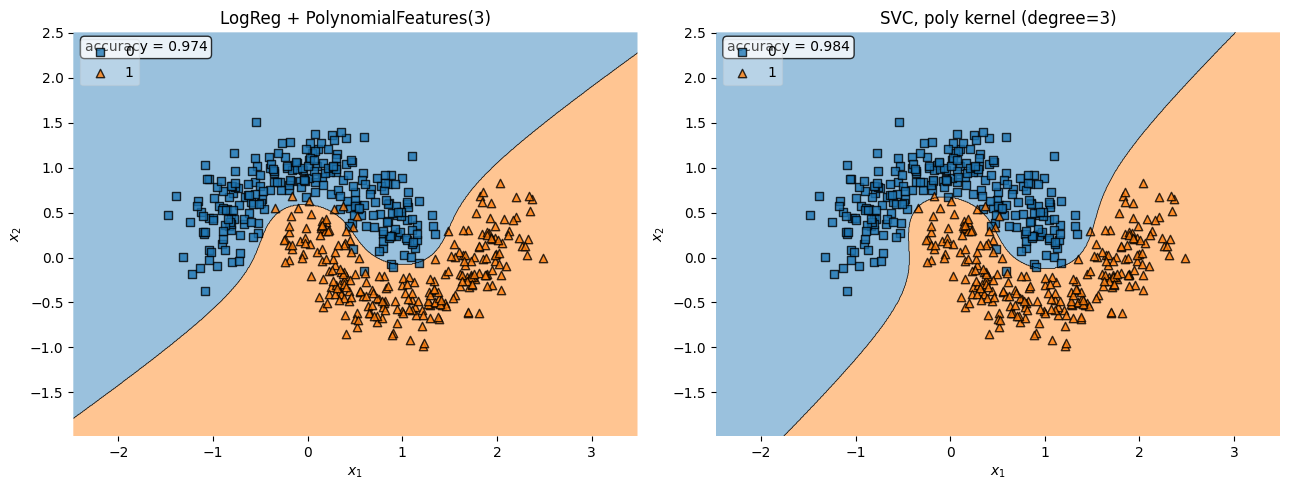

Признаков после PolynomialFeatures(3): 9 (было 2)
LogReg + Poly(3):      train acc = 0.974, CV acc = 0.976, f1_macro = 0.974
SVC poly (degree=3):   train acc = 0.984, CV acc = 0.972, f1_macro = 0.984


In [6]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# Та же степень, что выбрана для полиномиального ядра в 1.2.
POLY_DEGREE = 3

poly_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=POLY_DEGREE, include_bias=False)),
    ('log_reg', LogisticRegression(C=1.0, max_iter=1000)),
])

poly_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(kernel='poly', degree=POLY_DEGREE, C=10, coef0=1.0)),
])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
acc_lr = plot_decisions(poly_lr, moons_points, moons_labels,
                        'LogReg + PolynomialFeatures(%d)' % POLY_DEGREE, ax=axes[0])
acc_svm = plot_decisions(poly_svm, moons_points, moons_labels,
                         'SVC, poly kernel (degree=%d)' % POLY_DEGREE, ax=axes[1])
plt.tight_layout()
plt.show()

cv_lr = cross_val_score(poly_lr, moons_points, moons_labels,
                        cv=5, scoring='accuracy').mean()
cv_svm = cross_val_score(poly_svm, moons_points, moons_labels,
                         cv=5, scoring='accuracy').mean()

n_features = poly_lr.named_steps['poly'].fit(moons_points).n_output_features_
print('Признаков после PolynomialFeatures(%d): %d (было 2)'
      % (POLY_DEGREE, n_features))
print('LogReg + Poly(%d):      train acc = %.3f, CV acc = %.3f, f1_macro = %.3f'
      % (POLY_DEGREE, acc_lr, cv_lr,
         f1_score(moons_labels, poly_lr.predict(moons_points), average='macro')))
print('SVC poly (degree=%d):   train acc = %.3f, CV acc = %.3f, f1_macro = %.3f'
      % (POLY_DEGREE, acc_svm, cv_svm,
         f1_score(moons_labels, poly_svm.predict(moons_points), average='macro')))


**Результаты.**

| Модель | CV accuracy | train accuracy | `f1_macro` (train) |
|---|---|---|---|
| LogReg + `PolynomialFeatures(3)` | 0.976 | 0.974 | 0.974 |
| SVC, `poly` kernel (`degree=3`) | 0.972 | 0.984 | 0.984 |

`PolynomialFeatures(3)` превращает 2 признака в 9: `x1, x2, x1², x1x2, x2², x1³, x1²x2, x1x2², x2³`. LogReg в этом пространстве строит ту же кубическую кривую, что и SVC с полиномиальным ядром `degree=3`: качество совпадает в пределах шума, а области решений визуально почти неотличимы.

**Почему это «ручной kernel trick».** Полиномиальное ядро $K(x,z)=(\gamma\langle x,z\rangle + c)^d$ соответствует скалярному произведению в пространстве всех мономов степени $\le d$: SVM находит ту же разделяющую поверхность, что и линейная модель после явного `PolynomialFeatures`. Разница только в цене: признаки строятся явно, и их число растёт как $O(p^d)$ — для 2 признаков это 9, а для 20 признаков и `degree=4` уже 10 625. Ядро же считает только скалярные произведения на парах объектов и хранит лишь опорные векторы.


## 1.4 Harder problem

Let's make this task a bit more challenging via upgrading dataset:

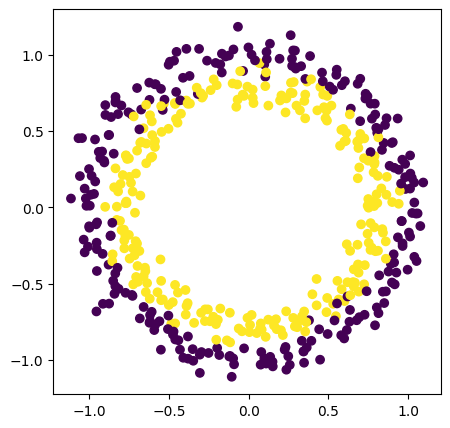

In [7]:
from sklearn.datasets import make_circles

circles_points, circles_labels = make_circles(n_samples=500, noise=0.06, random_state=42)

plt.figure(figsize=(5, 5))
plt.scatter(circles_points[:, 0], circles_points[:, 1], c=circles_labels)

And even more:

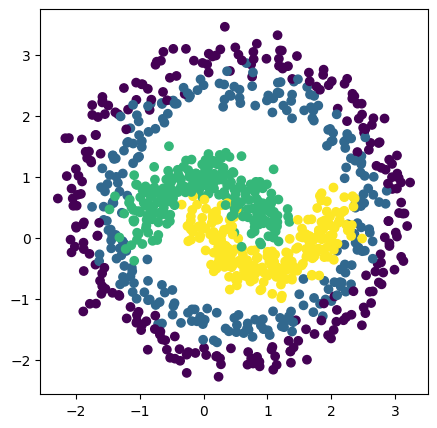

In [8]:
points = np.vstack((circles_points*2.5 + 0.5, moons_points))
labels = np.hstack((circles_labels, moons_labels + 2)) # + 2 to distinct moons classes

plt.figure(figsize=(5, 5))
plt.scatter(points[:, 0], points[:, 1], c=labels)

Now do your best using all the approaches above!

Tune LR with generated features, SVM with appropriate kernel of your choice. You may add some of your loved models to demonstrate their (and your) strength. Again plot decision regions, calculate metric.

Justify the results in a few phrases.

LogReg + Poly(3)                   train acc = 0.912, CV acc = 0.902, f1_macro = 0.912
LogReg + Poly(4)                   train acc = 0.931, CV acc = 0.928, f1_macro = 0.931
SVC rbf, {'svc__C': 10, 'svc__gamma': 1.0} train acc = 0.943, CV acc = 0.934, f1_macro = 0.943
RandomForest(300)                  train acc = 1.000, CV acc = 0.909, f1_macro = 1.000
RBF без масштабирования: CV acc = 0.927


/opt/anaconda3/envs/lab_01/lib/python3.10/site-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/opt/anaconda3/envs/lab_01/lib/python3.10/site-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(
/opt/anaconda3/envs/lab_01/lib/python3.10/site-packages/mlxtend/plotting/decision_regions.py:346: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


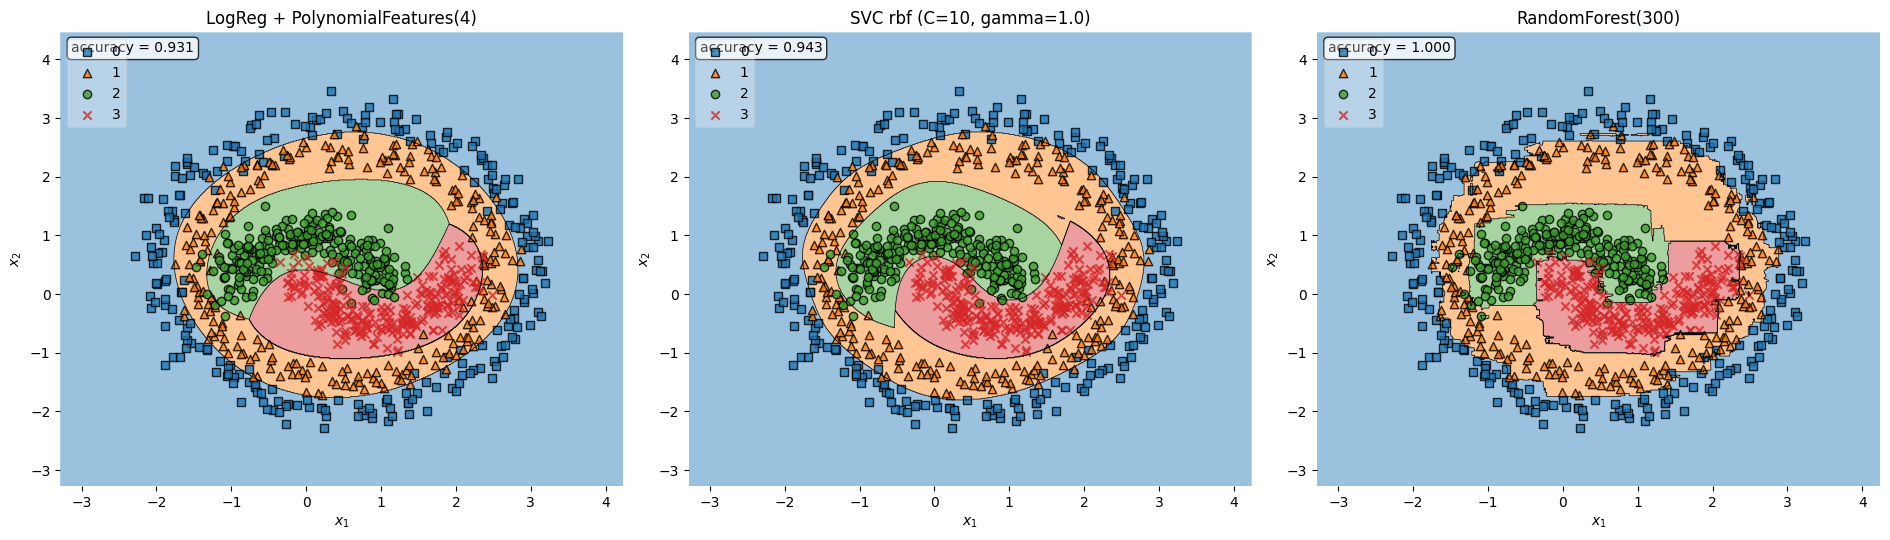

In [9]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, cross_val_score

# Круги растянуты в 2.5 раза и сдвинуты, поэтому масштабирование обязательно:
# без него RBF-ядро «видит» круги в другом масштабе, чем «луны».
hard_lr = {
    degree: Pipeline([
        ('scaler', StandardScaler()),
        ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
        ('log_reg', LogisticRegression(C=1.0, max_iter=2000)),
    ])
    for degree in (3, 4)
}

rbf_search = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='rbf'))]),
    {'svc__C': [1, 10, 100], 'svc__gamma': ['scale', 0.5, 1.0, 2.0]},
    cv=5, scoring='accuracy',
)
rbf_search.fit(points, labels)

rf = RandomForestClassifier(n_estimators=300, random_state=42)

models = {
    'LogReg + Poly(3)': hard_lr[3],
    'LogReg + Poly(4)': hard_lr[4],
    'SVC rbf, %s' % rbf_search.best_params_: rbf_search.best_estimator_,
    'RandomForest(300)': rf,
}

for name, model in models.items():
    model.fit(points, labels)
    cv_acc = cross_val_score(model, points, labels, cv=5, scoring='accuracy').mean()
    print('%-34s train acc = %.3f, CV acc = %.3f, f1_macro = %.3f'
          % (name, accuracy_score(labels, model.predict(points)), cv_acc,
             f1_score(labels, model.predict(points), average='macro')))

# Проверяем, что масштабирование действительно важно для RBF.
rbf_no_scaler = SVC(kernel='rbf', **{k.replace('svc__', ''): v
                                     for k, v in rbf_search.best_params_.items()})
print('RBF без масштабирования: CV acc = %.3f'
      % cross_val_score(rbf_no_scaler, points, labels, cv=5,
                        scoring='accuracy').mean())

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
plot_decisions(hard_lr[4], points, labels, 'LogReg + PolynomialFeatures(4)', ax=axes[0])
plot_decisions(rbf_search.best_estimator_, points, labels,
               'SVC rbf (C=%s, gamma=%s)' % (rbf_search.best_params_['svc__C'],
                                             rbf_search.best_params_['svc__gamma']),
               ax=axes[1])
plot_decisions(RandomForestClassifier(n_estimators=300, random_state=42),
               points, labels, 'RandomForest(300)', ax=axes[2])
plt.tight_layout()
plt.show()


**Результаты.**

| Модель | CV accuracy | train accuracy | `f1_macro` (train) |
|---|---|---|---|
| LogReg + `PolynomialFeatures(3)` | 0.902 | 0.912 | 0.912 |
| LogReg + `PolynomialFeatures(4)` | 0.928 | 0.931 | 0.931 |
| SVC `rbf` (`C=10`, `gamma=1`) | **0.934** | 0.943 | 0.943 |
| RandomForest (300 деревьев) | 0.909 | 1.000 | 1.000 |

Масштабирование действительно важно: тот же `rbf` без `StandardScaler` даёт CV 0.927 против 0.934.

**Почему `rbf` лучше остальных.** В наборе четыре класса в двух разных масштабах: круги растянуты в 2.5 раза, и один параметр `gamma` должен описывать области разного размера. Глобальная полиномиальная модель вынуждена описывать все четыре класса одной поверхностью фиксированной степени: `degree=3` нечётный и плохо подходит для почти круговой границы (0.902), `degree=4` уже лучше (0.928), но всё ещё нелокален. `rbf` строит локальную границу вокруг каждого класса и легко совмещает оба масштаба — 0.934. RandomForest даёт ступенчатую, ось-параллельную границу, поэтому диагональные дуги «лун» и круги аппроксимирует грубо; train accuracy 1.000 при CV 0.909 — классическое переобучение, и это худший результат среди нелинейных моделей.

**Вывод.** Задача заметно сложнее предыдущей: в одном наборе два масштаба и четыре класса, поэтому даже лучшая модель даёт ≈0.93 вместо ≈0.98. `rbf` выигрывает за счёт локальности, полиномиальная LogReg ограничена глобальной поверхностью фиксированной степени, а RandomForest приближает плавные границы ступенчатой сеткой и переобучается.
